# Respiratory Disease Diagnosis with a Bayesian Network
### Exact Inference by Variable Elimination (from scratch) — organised with the Interpretable Context Methodology (ICM)

| | |
|---|---|
| **Student** | Shivprakash (MIS 612302059) |
| **Institute** | COEP Technological University, Pune — B.Tech (Robotics & AI), T.Y. |
| **Course / Evaluation** | Advanced Artificial Intelligence (MRAIPEC702-A) — TA-2 |
| **Syllabus topic** | Unit 1 — Probability Theory and Exact Inference (Bayesian networks, d-separation, variable elimination) |
| **Tools** | Python 3, NumPy, NetworkX, Matplotlib, pgmpy (only for cross-checking) |

## 1. Why this project?
In **TA-1** we analysed the research paper *"Interpretable Context Methodology: Folder Structure as Agentic Architecture"* (arXiv 2603.16021).
ICM organises a workflow as a **folder of stages**: each stage does **one job**, talks to the next stage through **plain-text files** (markdown / JSON),
and loads **only the context it needs** (layered context loading).

**TA-2 applies that idea to a medical reasoning problem.** A Bayesian network is a natural fit for diagnosis (uncertain symptoms, causes and test results), and ICM
makes every step of our pipeline *inspectable*: any intermediate result is a text file a human can open and check.

| ICM principle | How it is used here |
|---|---|
| One stage, one job | `01_structure` → `02_cpts` → `03_inference` → `04_independence` → `05_verification` → `06_report`, each a separate folder |
| Plain text as the interface | Network, probabilities, queries, results and report are all `.json` / `.md` files |
| Layered context loading | `run_stage()` hands a stage **only** the files it declares as inputs |
| Human-inspectable output | Every elimination step of every query is logged in `results.json` |

## 2. The medical model (Asia / "Chest Clinic" network)
Classic textbook network by Lauritzen & Spiegelhalter (1988), used for **learning purposes only — not clinical advice**.

* `asia` – recent visit to Asia (TB risk) · `smoke` – smoker
* `tub` – tuberculosis · `lung` – lung cancer · `bronc` – bronchitis
* `either` – tuberculosis **or** lung cancer (deterministic OR node)
* `xray` – positive chest X-ray · `dysp` – dyspnoea (shortness of breath)

The joint distribution factorises along the DAG:

$$P(A,S,T,L,B,E,X,D)=P(A)\,P(S)\,P(T|A)\,P(L|S)\,P(B|S)\,P(E|T,L)\,P(X|E)\,P(D|B,E)$$

## 3. Setup and the ICM stage runner

In [1]:
import json, shutil, re, time
from itertools import combinations, product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

WS = Path("icm_workspace_respiratory")          # the ICM workspace = a folder tree
if WS.exists():
    shutil.rmtree(WS)
WS.mkdir()

def write_text(rel, text):
    p = WS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(text, encoding="utf-8")
    return p

def run_stage(name, inputs, fn, output):
    """ICM stage runner  ->  ONE stage, ONE job.
    The stage receives ONLY the files it declares as inputs (layered context loading)
    and writes exactly ONE plain-text output file."""
    loaded = {rel: (WS / rel).read_text(encoding="utf-8") for rel in inputs}
    out_text = fn(loaded)
    write_text(output, out_text)
    print(f"[{name:<16}] inputs={len(inputs)} ({sum(map(len, loaded.values()))} chars)  ->  {output}  ({len(out_text)} chars)")
    return out_text

## 4. Stage 00 — Context (reference material)
In ICM, *reference material* (rules, constraints, definitions) is kept separate from *working artifacts*. This file is the only hand-written context; later stages read from it.

In [2]:
CONTEXT = """# Context: respiratory diagnosis Bayesian network

PURPOSE: Educational Bayesian network for chest-clinic diagnosis (Asia network, Lauritzen & Spiegelhalter 1988).
NOT FOR CLINICAL USE.

STATES: no, yes
RULES:
- Every variable is binary; state order is [no, yes].
- The graph must be a DAG (no cycles).
- Every CPT row must sum to 1.
- Inference is exact (variable elimination); results are cross-checked by brute force and by pgmpy.
"""
write_text("00_context/CONTEXT.md", CONTEXT)
print(CONTEXT)

# Context: respiratory diagnosis Bayesian network

PURPOSE: Educational Bayesian network for chest-clinic diagnosis (Asia network, Lauritzen & Spiegelhalter 1988).
NOT FOR CLINICAL USE.

STATES: no, yes
RULES:
- Every variable is binary; state order is [no, yes].
- The graph must be a DAG (no cycles).
- Every CPT row must sum to 1.
- Inference is exact (variable elimination); results are cross-checked by brute force and by pgmpy.



## 5. Stage 01 — Network structure
**Job:** turn the context into `network.json` (nodes, states, parents) and check the graph is a DAG.

[01_structure    ] inputs=1 (434 chars)  ->  01_structure/network.json  (1412 chars)


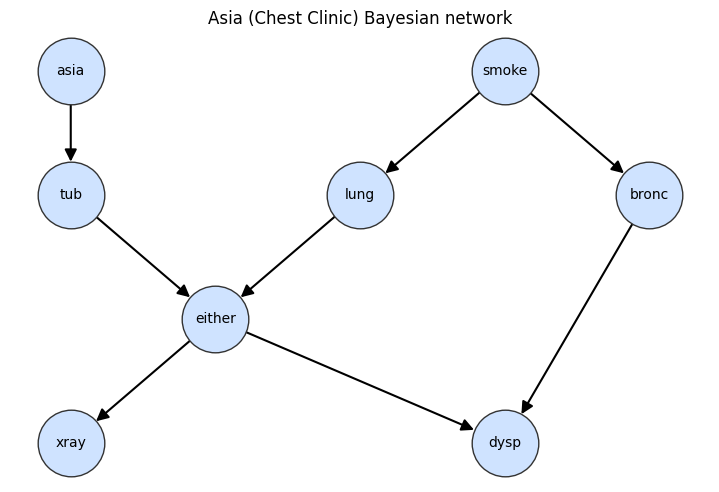

Topological order: ['asia', 'smoke', 'tub', 'lung', 'bronc', 'either', 'xray', 'dysp']


In [3]:
PARENTS = {
    "asia":   [],
    "smoke":  [],
    "tub":    ["asia"],
    "lung":   ["smoke"],
    "bronc":  ["smoke"],
    "either": ["tub", "lung"],
    "xray":   ["either"],
    "dysp":   ["bronc", "either"],
}
LABELS = {
    "asia": "Recent visit to Asia", "smoke": "Smoker", "tub": "Tuberculosis",
    "lung": "Lung cancer", "bronc": "Bronchitis", "either": "Tuberculosis OR lung cancer",
    "xray": "Positive chest X-ray", "dysp": "Dyspnoea (breathlessness)",
}

def stage_structure(loaded):
    ctx = loaded["00_context/CONTEXT.md"]
    states = [s.strip() for s in re.search(r"STATES:(.*)", ctx).group(1).split(",")]
    g = nx.DiGraph([(p, c) for c, ps in PARENTS.items() for p in ps])
    g.add_nodes_from(PARENTS)
    assert nx.is_directed_acyclic_graph(g), "Network contains a cycle!"
    net = {"name": "Asia (Chest Clinic) network",
           "topological_order": list(nx.topological_sort(g)),
           "nodes": {v: {"label": LABELS[v], "states": states, "parents": PARENTS[v]} for v in PARENTS}}
    return json.dumps(net, indent=2)

_ = run_stage("01_structure", ["00_context/CONTEXT.md"], stage_structure, "01_structure/network.json")

# --- draw the DAG ---
net = json.loads((WS / "01_structure/network.json").read_text())
G = nx.DiGraph([(p, c) for c, d in net["nodes"].items() for p in d["parents"]])
pos = {"asia": (0, 3), "smoke": (3, 3), "tub": (0, 2), "lung": (2, 2), "bronc": (4, 2),
       "either": (1, 1), "xray": (0, 0), "dysp": (3, 0)}
plt.figure(figsize=(7, 4.5))
nx.draw(G, pos, with_labels=True, node_size=2300, node_color="#cfe3ff", edgecolors="#333",
        font_size=10, arrowsize=18, width=1.5)
plt.title("Asia (Chest Clinic) Bayesian network"); plt.show()
print("Topological order:", net["topological_order"])

## 6. Stage 02 — Conditional probability tables (CPTs)
**Job:** attach a CPT to each node, validate it against the structure (all parent combinations present, rows sum to 1) and write `cpts.json`.
Key format: parent states joined by `|` in the order the parents are listed; each row is `[P(no), P(yes)]`.

In [4]:
CPT_SPEC = {
    "asia":   {"": [0.99, 0.01]},
    "smoke":  {"": [0.50, 0.50]},
    "tub":    {"no": [0.99, 0.01], "yes": [0.95, 0.05]},                 # P(tub | asia)
    "lung":   {"no": [0.99, 0.01], "yes": [0.90, 0.10]},                 # P(lung | smoke)
    "bronc":  {"no": [0.70, 0.30], "yes": [0.40, 0.60]},                 # P(bronc | smoke)
    "either": {"no|no": [1, 0], "no|yes": [0, 1], "yes|no": [0, 1], "yes|yes": [0, 1]},   # tub OR lung
    "xray":   {"no": [0.95, 0.05], "yes": [0.02, 0.98]},                 # P(xray | either)
    "dysp":   {"no|no": [0.90, 0.10], "no|yes": [0.30, 0.70],            # P(dysp | bronc, either)
               "yes|no": [0.20, 0.80], "yes|yes": [0.10, 0.90]},
}

def stage_cpts(loaded):
    net = json.loads(loaded["01_structure/network.json"])
    out = {}
    for v, d in net["nodes"].items():
        expected = ["|".join(c) for c in product(*[net["nodes"][p]["states"] for p in d["parents"]])] or [""]
        assert sorted(CPT_SPEC[v]) == sorted(expected), f"{v}: parent configurations do not match"
        for key, row in CPT_SPEC[v].items():
            assert len(row) == len(d["states"]) and abs(sum(row) - 1) < 1e-9, f"{v}[{key}] does not sum to 1"
        out[v] = CPT_SPEC[v]
    return json.dumps({"validated": True, "cpts": out}, indent=2)

_ = run_stage("02_cpts", ["01_structure/network.json"], stage_cpts, "02_cpts/cpts.json")

# readable view of two CPTs
print("P(dyspnoea=yes | bronchitis, either):")
display(pd.DataFrame([{"bronc": k.split("|")[0], "either": k.split("|")[1], "P(dysp=yes)": r[1]}
                      for k, r in CPT_SPEC["dysp"].items()]))

[02_cpts         ] inputs=1 (1412 chars)  ->  02_cpts/cpts.json  (1094 chars)
P(dyspnoea=yes | bronchitis, either):


,bronc,either,P(dysp=yes)
0,no,no,0.1
1,no,yes,0.7
2,yes,no,0.8
3,yes,yes,0.9


## 7. The inference engine (written from scratch)
Three ideas are needed:

1. **Factor** – a table over a set of variables. Initially one factor per CPT.
2. **Factor product** `φ₁ × φ₂` and **marginalisation** `Σ_X φ` (sum a variable out).
3. **Variable elimination (VE)** – to answer `P(Q | e)`:
   1. *Reduce* every factor by the evidence `e`.
   2. Pick a variable `X` that is neither the query nor evidence; multiply all factors that mention `X`; sum `X` out (this creates a new factor).
   3. Repeat until only factors over `Q` remain; multiply them and **normalise**.

The sum of the unnormalised result is `P(e)`. The **elimination order** controls the size of the intermediate factors, so we use a greedy *min-degree* heuristic.

In [5]:
class Factor:
    """A table phi(vars) over discrete variables: a NumPy array with one axis per variable."""
    def __init__(self, variables, cards, table):
        self.vars = list(variables)
        self.cards = {v: cards[v] for v in self.vars}
        self.table = np.asarray(table, dtype=float).reshape([self.cards[v] for v in self.vars])

    def __mul__(self, other):                       # factor product
        all_vars = self.vars + [v for v in other.vars if v not in self.vars]
        letter = {v: chr(97 + i) for i, v in enumerate(all_vars)}
        spec = ("".join(letter[v] for v in self.vars) + "," + "".join(letter[v] for v in other.vars)
                + "->" + "".join(letter[v] for v in all_vars))
        return Factor(all_vars, {**self.cards, **other.cards}, np.einsum(spec, self.table, other.table))

    def sum_out(self, var):                         # marginalise one variable
        rest = [v for v in self.vars if v != var]
        return Factor(rest, self.cards, self.table.sum(axis=self.vars.index(var)))

    def reduce(self, var, state_idx):               # condition on evidence var = state
        rest = [v for v in self.vars if v != var]
        return Factor(rest, self.cards, np.take(self.table, state_idx, axis=self.vars.index(var)))

def build_factors(net, cpts):
    factors, states = [], {v: d["states"] for v, d in net["nodes"].items()}
    for v, d in net["nodes"].items():
        scope = d["parents"] + [v]
        cards = {u: len(states[u]) for u in scope}
        t = np.zeros([cards[u] for u in scope])
        for key, row in cpts[v].items():
            idx = tuple(states[p].index(s) for p, s in zip(d["parents"], key.split("|"))) if d["parents"] else ()
            t[idx] = row
        factors.append(Factor(scope, cards, t))
    return factors, states

def min_degree_order(factors, hidden):
    adj = {}
    for f in factors:
        for a in f.vars:
            adj.setdefault(a, set()).update(b for b in f.vars if b != a)
    order, remaining = [], set(hidden)
    while remaining:
        v = min(remaining, key=lambda x: (len(adj.get(x, ())), x))
        nbrs = adj.get(v, set())
        for a in nbrs:                              # connect neighbours (fill-in edges)
            adj[a].update(b for b in nbrs if b != a)
            adj[a].discard(v)
        remaining.discard(v); order.append(v)
    return order

def variable_elimination(factors, states, query, evidence):
    assert query not in evidence, "query variable cannot be evidence"
    fs = []
    for f in factors:                               # step 1: reduce by evidence
        for v, s in evidence.items():
            if v in f.vars:
                f = f.reduce(v, states[v].index(s))
        fs.append(f)
    hidden = [v for v in states if v != query and v not in evidence]
    order = min_degree_order(fs, hidden)
    trace = []
    for v in order:                                 # step 2: eliminate one hidden variable at a time
        involved = [f for f in fs if v in f.vars]
        fs = [f for f in fs if v not in f.vars]
        prod = involved[0]
        for f in involved[1:]:
            prod = prod * f
        new = prod.sum_out(v)
        trace.append({"eliminate": v,
                      "multiplied_factors": [f.vars for f in involved],
                      "product_scope": prod.vars, "product_size": int(prod.table.size),
                      "new_factor_scope": new.vars})
        fs.append(new)
    result = fs[0]                                  # step 3: multiply what is left and normalise
    for f in fs[1:]:
        result = result * f
    p_e = float(result.table.sum())
    posterior = None if p_e == 0 else dict(zip(states[query], (result.table / p_e).tolist()))
    return {"posterior": posterior, "p_evidence": p_e, "order": order, "trace": trace}

def brute_force(factors, states, query, evidence):
    """Reference answer: build the FULL joint table, then slice and sum (exponential, only OK for small nets)."""
    joint = factors[0]
    for f in factors[1:]:
        joint = joint * f
    idx = tuple(states[v].index(evidence[v]) if v in evidence else slice(None) for v in joint.vars)
    sub = joint.table[idx]
    remaining = [v for v in joint.vars if v not in evidence]
    axes = tuple(i for i, v in enumerate(remaining) if v != query)
    marg = sub.sum(axis=axes) if axes else sub
    return dict(zip(states[query], (marg / marg.sum()).tolist()))

# sanity check: the joint must sum to 1
net = json.loads((WS / "01_structure/network.json").read_text())
cpts = json.loads((WS / "02_cpts/cpts.json").read_text())["cpts"]
factors, states = build_factors(net, cpts)
joint = factors[0]
for f in factors[1:]:
    joint = joint * f
print("Joint table size:", joint.table.shape, "| sum of joint =", round(float(joint.table.sum()), 12))

Joint table size: (2, 2, 2, 2, 2, 2, 2, 2) | sum of joint = 1.0


## 8. Stage 03 — Inference queries
**Job:** run the queries listed in `queries.json` with variable elimination and record posteriors, `P(evidence)` and the full elimination trace in `results.json`.
The queries cover the three classic reasoning patterns: *predictive* (cause → effect), *diagnostic* (effect → cause) and *explaining away* (intercausal).

In [6]:
QUERIES = [
    {"id": "Q1", "type": "prior",       "query": "lung",  "evidence": {},
     "question": "What is the prior probability of lung cancer?"},
    {"id": "Q2", "type": "predictive",  "query": "dysp",  "evidence": {"smoke": "yes"},
     "question": "How likely is dyspnoea for a smoker?"},
    {"id": "Q3", "type": "diagnostic",  "query": "lung",  "evidence": {"xray": "yes"},
     "question": "Positive X-ray: probability of lung cancer?"},
    {"id": "Q4", "type": "diagnostic",  "query": "lung",  "evidence": {"smoke": "yes", "xray": "yes", "dysp": "yes"},
     "question": "Smoker with positive X-ray and dyspnoea: probability of lung cancer?"},
    {"id": "Q5", "type": "diagnostic",  "query": "tub",   "evidence": {"asia": "yes", "xray": "yes"},
     "question": "Visited Asia and positive X-ray: probability of tuberculosis?"},
    {"id": "Q6", "type": "diagnostic",  "query": "bronc", "evidence": {"smoke": "yes", "dysp": "yes"},
     "question": "Smoker with dyspnoea: probability of bronchitis?"},
    {"id": "Q7", "type": "explaining-away", "query": "tub", "evidence": {"either": "yes"},
     "question": "Either TB or cancer present: probability of tuberculosis?"},
    {"id": "Q8", "type": "explaining-away", "query": "tub", "evidence": {"either": "yes", "lung": "yes"},
     "question": "Either present AND lung cancer confirmed: probability of tuberculosis?"},
]
write_text("03_inference/queries.json", json.dumps(QUERIES, indent=2))

def stage_inference(loaded):
    net = json.loads(loaded["01_structure/network.json"])
    cpts = json.loads(loaded["02_cpts/cpts.json"])["cpts"]
    queries = json.loads(loaded["03_inference/queries.json"])
    factors, states = build_factors(net, cpts)
    results = []
    for q in queries:
        t0 = time.perf_counter()
        r = variable_elimination(factors, states, q["query"], q["evidence"])
        r.update(id=q["id"], type=q["type"], question=q["question"], query=q["query"],
                 evidence=q["evidence"], max_factor_size=max([s["product_size"] for s in r["trace"]] or [0]),
                 seconds=round(time.perf_counter() - t0, 6))
        results.append(r)
    return json.dumps(results, indent=2)

_ = run_stage("03_inference", ["01_structure/network.json", "02_cpts/cpts.json", "03_inference/queries.json"],
              stage_inference, "03_inference/results.json")

results = json.loads((WS / "03_inference/results.json").read_text())
display(pd.DataFrame([{"id": r["id"], "type": r["type"], "query": r["query"],
                       "evidence": ", ".join(f"{k}={v}" for k, v in r["evidence"].items()) or "-",
                       "P(query=yes | e)": round(r["posterior"]["yes"], 4),
                       "P(e)": round(r["p_evidence"], 4),
                       "elimination order": " > ".join(r["order"]) or "-"} for r in results]))

[03_inference    ] inputs=3 (4114 chars)  ->  03_inference/results.json  (20389 chars)


,id,type,query,evidence,P(query=yes | e),P(e),elimination order
0,Q1,prior,lung,-,0.0550,1.0000,asia > xray > dysp > bronc > smoke > either > tub
1,Q2,predictive,dysp,smoke=yes,0.5528,0.5000,asia > xray > bronc > lung > tub > either
2,Q3,diagnostic,lung,xray=yes,0.4887,0.1103,asia > dysp > bronc > smoke > either > tub
3,Q4,diagnostic,lung,"smoke=yes, xray=yes, dysp=yes",0.7237,0.0555,asia > bronc > either > tub
4,Q5,diagnostic,tub,"asia=yes, xray=yes",0.3377,0.0015,dysp > bronc > smoke > either > lung
5,Q6,diagnostic,bronc,"smoke=yes, dysp=yes",0.8802,0.2764,asia > xray > lung > tub > either
6,Q7,explaining-away,tub,either=yes,0.1604,0.0648,xray > asia > dysp > bronc > smoke > lung
7,Q8,explaining-away,tub,"either=yes, lung=yes",0.0104,0.0550,xray > asia > dysp > bronc > smoke


### 8.1 Looking inside one query (interpretability)
ICM insists that every intermediate artifact is readable. Here is the full elimination trace for **Q4** (smoker + positive X-ray + dyspnoea → lung cancer):

In [7]:
q4 = next(r for r in results if r["id"] == "Q4")
print("Query: P(lung | smoke=yes, xray=yes, dysp=yes)  =", {k: round(v, 4) for k, v in q4["posterior"].items()})
print("Elimination order:", q4["order"], "\n")
for i, s in enumerate(q4["trace"], 1):
    print(f"step {i}: eliminate {s['eliminate']:<7} multiply {s['multiplied_factors']}  "
          f"-> table over {s['product_scope']} (size {s['product_size']})  -> new factor over {s['new_factor_scope']}")

Query: P(lung | smoke=yes, xray=yes, dysp=yes)  = {'no': 0.2763, 'yes': 0.7237}
Elimination order: ['asia', 'bronc', 'either', 'tub'] 

step 1: eliminate asia    multiply [['asia'], ['asia', 'tub']]  -> table over ['asia', 'tub'] (size 4)  -> new factor over ['tub']
step 2: eliminate bronc   multiply [['bronc'], ['bronc', 'either']]  -> table over ['bronc', 'either'] (size 4)  -> new factor over ['either']
step 3: eliminate either  multiply [['tub', 'lung', 'either'], ['either'], ['either']]  -> table over ['tub', 'lung', 'either'] (size 8)  -> new factor over ['tub', 'lung']
step 4: eliminate tub     multiply [['tub'], ['tub', 'lung']]  -> table over ['tub', 'lung'] (size 4)  -> new factor over ['lung']


**Explaining away (Q7 vs Q8).** `tub` and `lung` are independent a priori, but both cause `either`. Once `either=yes` is observed, evidence for one cause *lowers* belief in the other.
If `lung=yes` is confirmed, the OR node is already explained, so `P(tub)` should fall back to its prior `P(tub)=0.0104`. Let's check:

In [8]:
p_tub_prior = variable_elimination(factors, states, "tub", {})["posterior"]["yes"]
q7 = next(r for r in results if r["id"] == "Q7")["posterior"]["yes"]
q8 = next(r for r in results if r["id"] == "Q8")["posterior"]["yes"]
print(f"P(tub=yes)                          = {p_tub_prior:.4f}   (prior)")
print(f"P(tub=yes | either=yes)             = {q7:.4f}   (cause is now suspected)")
print(f"P(tub=yes | either=yes, lung=yes)   = {q8:.4f}   (explained away -> back to the prior)")
assert abs(q8 - p_tub_prior) < 1e-12

P(tub=yes)                          = 0.0104   (prior)
P(tub=yes | either=yes)             = 0.1604   (cause is now suspected)
P(tub=yes | either=yes, lung=yes)   = 0.0104   (explained away -> back to the prior)


## 9. Stage 04 — Conditional independence (d-separation)
**Job:** test independence statements read from the graph alone. Algorithm used (moralised ancestral graph):
1. keep only `X ∪ Y ∪ Z` and their ancestors; 2. *marry* parents of every node and drop directions; 3. delete the nodes in `Z`;
4. `X ⟂ Y | Z` iff `X` and `Y` are disconnected. Results are compared with NetworkX's built-in test.

In [9]:
def d_separated(parents, X, Y, Z):
    X, Y, Z = set(X), set(Y), set(Z)
    anc, stack = set(), list(X | Y | Z)
    while stack:                                    # 1. ancestral set
        n = stack.pop()
        if n not in anc:
            anc.add(n); stack.extend(parents[n])
    adj = {n: set() for n in anc}
    for n in anc:                                   # 2. moralise
        for p in parents[n]:
            adj[n].add(p); adj[p].add(n)
        for a, b in combinations(parents[n], 2):
            adj[a].add(b); adj[b].add(a)
    seen, stack = set(), [x for x in X if x not in Z]   # 3-4. remove Z, test connectivity
    while stack:
        n = stack.pop()
        if n in seen: continue
        seen.add(n)
        stack.extend(m for m in adj[n] if m not in Z and m not in seen)
    return not (seen & Y)

def nx_check(parents, X, Y, Z):
    g = nx.DiGraph([(p, c) for c, ps in parents.items() for p in ps]); g.add_nodes_from(parents)
    fn = getattr(nx, "is_d_separator", None) or nx.d_separated
    return fn(g, set(X), set(Y), set(Z))

TESTS = [
    (["asia"],  ["smoke"], [],                    "no common cause or effect"),
    (["tub"],   ["lung"],  [],                    "collider 'either' unobserved -> blocked"),
    (["tub"],   ["lung"],  ["either"],            "collider observed -> OPENS (explaining away)"),
    (["xray"],  ["dysp"],  ["either"],            "common cause observed -> blocked"),
    (["xray"],  ["bronc"], [],                    "path via lung<-smoke->bronc is open"),
    (["xray"],  ["bronc"], ["smoke"],             "common cause 'smoke' observed -> blocked"),
    (["xray"],  ["bronc"], ["smoke", "dysp"],     "collider 'dysp' observed -> opens"),
    (["asia"],  ["dysp"],  ["either"],            "chain asia>tub>either>dysp is blocked, BUT observed collider 'either' opens asia>tub>either<lung<smoke>bronc>dysp"),
    (["asia"],  ["smoke"], ["dysp"],              "descendant of collider observed -> opens"),
]

def stage_independence(loaded):
    net = json.loads(loaded["01_structure/network.json"])
    parents = {v: d["parents"] for v, d in net["nodes"].items()}
    rows = []
    for X, Y, Z, why in TESTS:
        mine, ref = d_separated(parents, X, Y, Z), nx_check(parents, X, Y, Z)
        rows.append({"X": X[0], "Y": Y[0], "given": Z, "independent": mine, "networkx_agrees": mine == ref, "reason": why})
    return json.dumps(rows, indent=2)

_ = run_stage("04_independence", ["01_structure/network.json"], stage_independence, "04_independence/independence.json")
ind = pd.DataFrame(json.loads((WS / "04_independence/independence.json").read_text()))
display(ind)
assert ind["networkx_agrees"].all()

[04_independence ] inputs=1 (1412 chars)  ->  04_independence/independence.json  (1720 chars)


,X,Y,given,independent,networkx_agrees,reason
0,asia,smoke,[],True,True,no common cause or effect
1,tub,lung,[],True,True,collider 'either' unobserved -> blocked
2,tub,lung,[either],False,True,collider observed -> OPENS (explaining away)
3,xray,dysp,[either],True,True,common cause observed -> blocked
4,xray,bronc,[],False,True,path via lung<-smoke->bronc is open
5,xray,bronc,[smoke],True,True,common cause 'smoke' observed -> blocked
6,xray,bronc,"[smoke, dysp]",False,True,collider 'dysp' observed -> opens
7,asia,dysp,[either],False,True,"chain asia>tub>either>dysp is blocked, BUT obs..."
8,asia,smoke,[dysp],False,True,descendant of collider observed -> opens


## 10. Stage 05 — Verification
**Job:** prove the engine is right. Every query is recomputed in two independent ways and compared with the VE result:
* **brute force** – full joint table, slice and sum;
* **pgmpy** – a well-tested library (`VariableElimination`).

In [10]:
import warnings; warnings.filterwarnings("ignore")
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

def build_pgmpy(net, cpts):
    model = DiscreteBayesianNetwork([(p, c) for c, d in net["nodes"].items() for p in d["parents"]])
    cpds = []
    for v, d in net["nodes"].items():
        keys = ["|".join(c) for c in product(*[net["nodes"][p]["states"] for p in d["parents"]])] or [""]
        values = np.array([cpts[v][k] for k in keys]).T          # columns = parent configurations
        names = {u: net["nodes"][u]["states"] for u in [v] + d["parents"]}
        cpds.append(TabularCPD(v, len(d["states"]), values,
                               evidence=d["parents"] or None,
                               evidence_card=[2] * len(d["parents"]) or None, state_names=names))
    model.add_cpds(*cpds); model.check_model()
    return model

def stage_verification(loaded):
    net = json.loads(loaded["01_structure/network.json"])
    cpts = json.loads(loaded["02_cpts/cpts.json"])["cpts"]
    results = json.loads(loaded["03_inference/results.json"])
    factors, states = build_factors(net, cpts)
    infer = VariableElimination(build_pgmpy(net, cpts))
    rows = []
    for r in results:
        bf = brute_force(factors, states, r["query"], r["evidence"])
        pg = infer.query([r["query"]], evidence=r["evidence"], show_progress=False)
        pg_vals = dict(zip(pg.state_names[r["query"]], pg.values.tolist()))
        d_bf = max(abs(r["posterior"][s] - bf[s]) for s in bf)
        d_pg = max(abs(r["posterior"][s] - pg_vals[s]) for s in pg_vals)
        rows.append({"id": r["id"], "VE_yes": r["posterior"]["yes"], "bruteforce_yes": bf["yes"],
                     "pgmpy_yes": pg_vals["yes"], "max_abs_diff_bruteforce": d_bf, "max_abs_diff_pgmpy": d_pg,
                     "pass": bool(d_bf < 1e-9 and d_pg < 1e-9)})
    return json.dumps(rows, indent=2)

_ = run_stage("05_verification",
              ["01_structure/network.json", "02_cpts/cpts.json", "03_inference/results.json"],
              stage_verification, "05_verification/verification.json")
ver = pd.DataFrame(json.loads((WS / "05_verification/verification.json").read_text()))
display(ver.style.format({c: "{:.6f}" for c in ["VE_yes", "bruteforce_yes", "pgmpy_yes"]} |
                         {c: "{:.1e}" for c in ["max_abs_diff_bruteforce", "max_abs_diff_pgmpy"]}))
print("All queries verified:", bool(ver["pass"].all()))
assert ver["pass"].all()

[05_verification ] inputs=3 (22895 chars)  ->  05_verification/verification.json  (1922 chars)


,id,VE_yes,bruteforce_yes,pgmpy_yes,max_abs_diff_bruteforce,max_abs_diff_pgmpy,pass
0,Q1,0.055000,0.055000,0.055000,6.9e-18,1.1e-16,True
1,Q2,0.552808,0.552808,0.552808,0.0e+00,5.6e-17,True
2,Q3,0.488711,0.488711,0.488711,0.0e+00,1.1e-16,True
3,Q4,0.723714,0.723714,0.723714,1.1e-16,0.0e+00,True
4,Q5,0.337716,0.337716,0.337716,1.1e-16,1.1e-16,True
5,Q6,0.880164,0.880164,0.880164,2.8e-17,0.0e+00,True
6,Q7,0.160425,0.160425,0.160425,2.8e-17,1.1e-16,True
7,Q8,0.010400,0.010400,0.010400,0.0e+00,1.1e-16,True


All queries verified: True


## 11. How does belief evolve as evidence arrives?
A doctor collects evidence step by step. The chart shows how the posterior of three diseases changes — each point is a separate exact-inference query.

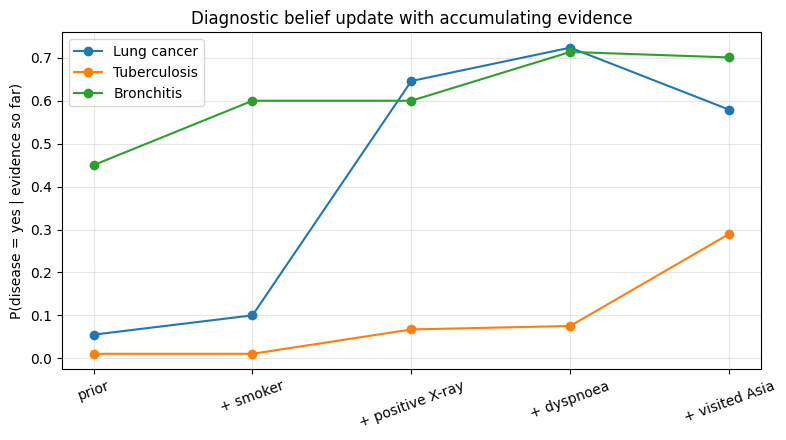

,lung,tub,bronc
prior,0.0550,0.0104,0.4500
+ smoker,0.1000,0.0104,0.6000
+ positive X-ray,0.6460,0.0672,0.6000
+ dyspnoea,0.7237,0.0753,0.7137
+ visited Asia,0.5792,0.2896,0.7009


In [11]:
steps = [("prior", {}),
         ("+ smoker", {"smoke": "yes"}),
         ("+ positive X-ray", {"smoke": "yes", "xray": "yes"}),
         ("+ dyspnoea", {"smoke": "yes", "xray": "yes", "dysp": "yes"}),
         ("+ visited Asia", {"smoke": "yes", "xray": "yes", "dysp": "yes", "asia": "yes"})]
curve = {d: [variable_elimination(factors, states, d, ev)["posterior"]["yes"] for _, ev in steps]
         for d in ["lung", "tub", "bronc"]}
names = {"lung": "Lung cancer", "tub": "Tuberculosis", "bronc": "Bronchitis"}

plt.figure(figsize=(8, 4.5))
for d, ys in curve.items():
    plt.plot([s for s, _ in steps], ys, marker="o", label=names[d])
plt.ylabel("P(disease = yes | evidence so far)"); plt.title("Diagnostic belief update with accumulating evidence")
plt.xticks(rotation=20); plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame(curve, index=[s for s, _ in steps]).round(4))

## 12. Stage 06 — Report
**Job:** compile the results and verification into a human-readable `report.md` (the final deliverable of the pipeline).

In [12]:
def stage_report(loaded):
    res = json.loads(loaded["03_inference/results.json"])
    ver = {v["id"]: v for v in json.loads(loaded["05_verification/verification.json"])}
    ind = json.loads(loaded["04_independence/independence.json"])
    L = ["# Respiratory diagnosis Bayesian network - report", "",
         "Exact inference by variable elimination (from scratch), cross-checked with brute force and pgmpy.",
         "_Educational model - not for clinical use._", "",
         "## Query results", "",
         "| ID | Type | Query | Evidence | P(yes) | P(evidence) | Verified |", "|---|---|---|---|---|---|---|"]
    for r in res:
        ev = ", ".join(f"{k}={v}" for k, v in r["evidence"].items()) or "-"
        L.append(f"| {r['id']} | {r['type']} | P({r['query']}) | {ev} | {r['posterior']['yes']:.4f} | "
                 f"{r['p_evidence']:.4f} | {'yes' if ver[r['id']]['pass'] else 'NO'} |")
    L += ["", "## Independence checks (d-separation)", "", "| X | Y | given | independent? |", "|---|---|---|---|"]
    for t in ind:
        L.append(f"| {t['X']} | {t['Y']} | {', '.join(t['given']) or '-'} | {t['independent']} |")
    L += ["", "## Key observation", "",
          "Explaining away: P(tub | either=yes) rises, but P(tub | either=yes, lung=yes) falls back to the prior."]
    return "\n".join(L)

report = run_stage("06_report",
                   ["03_inference/results.json", "04_independence/independence.json", "05_verification/verification.json"],
                   stage_report, "06_report/report.md")
print(report)

[06_report       ] inputs=3 (24031 chars)  ->  06_report/report.md  (1379 chars)
# Respiratory diagnosis Bayesian network - report

Exact inference by variable elimination (from scratch), cross-checked with brute force and pgmpy.
_Educational model - not for clinical use._

## Query results

| ID | Type | Query | Evidence | P(yes) | P(evidence) | Verified |
|---|---|---|---|---|---|---|
| Q1 | prior | P(lung) | - | 0.0550 | 1.0000 | yes |
| Q2 | predictive | P(dysp) | smoke=yes | 0.5528 | 0.5000 | yes |
| Q3 | diagnostic | P(lung) | xray=yes | 0.4887 | 0.1103 | yes |
| Q4 | diagnostic | P(lung) | smoke=yes, xray=yes, dysp=yes | 0.7237 | 0.0555 | yes |
| Q5 | diagnostic | P(tub) | asia=yes, xray=yes | 0.3377 | 0.0015 | yes |
| Q6 | diagnostic | P(bronc) | smoke=yes, dysp=yes | 0.8802 | 0.2764 | yes |
| Q7 | explaining-away | P(tub) | either=yes | 0.1604 | 0.0648 | yes |
| Q8 | explaining-away | P(tub) | either=yes, lung=yes | 0.0104 | 0.0550 | yes |

## Independence checks (d-separation

## 13. Final workspace (the ICM folder tree)

In [13]:
for p in sorted(WS.rglob("*")):
    depth = len(p.relative_to(WS).parts) - 1
    print("    " * depth + ("📁 " if p.is_dir() else "📄 ") + p.name + ("" if p.is_dir() else f"  ({p.stat().st_size} bytes)"))

📁 00_context
    📄 CONTEXT.md  (434 bytes)
📁 01_structure
    📄 network.json  (1412 bytes)
📁 02_cpts
    📄 cpts.json  (1094 bytes)
📁 03_inference
    📄 queries.json  (1608 bytes)
    📄 results.json  (20389 bytes)
📁 04_independence
    📄 independence.json  (1720 bytes)
📁 05_verification
    📄 verification.json  (1922 bytes)
📁 06_report
    📄 report.md  (1379 bytes)


## 14. Conclusions
* Implemented a **Bayesian network** for respiratory diagnosis and solved **exact inference from scratch** (factors, product, marginalisation, min-degree variable elimination).
* Results were **verified** against brute-force enumeration and pgmpy to machine precision.
* Showed the three reasoning patterns — **predictive, diagnostic and explaining-away** — and read independences directly off the graph with **d-separation**.
* The **ICM** structure (one stage = one folder = one job, plain-text hand-offs, only declared inputs loaded) made every intermediate result transparent and auditable — the interpretability goal of the TA-1 paper.

**Limitations / future work:** the CPTs are textbook values, not learned from patient data; exact VE becomes expensive for large networks (see approximate inference, Unit 3); a clinical system would need validated probabilities and expert review.

**References:** Lauritzen & Spiegelhalter (1988), *Local computations with probabilities on graphical structures*; Koller & Friedman (2009), *Probabilistic Graphical Models*; *Interpretable Context Methodology: Folder Structure as Agentic Architecture*, arXiv:2603.16021.